# **Airline Tweet Sentiment Classification with Deep Learning**


*   WALID M. W. KOBAHALABI - Software Persona AI Internship
*   halabiw04@gmail.com

**Dataset:**

> Twitter US Airline Sentiment (Kaggle, crowdflower/twitter-airline-sentiment).


**Task:**

> Classify each tweet as negative, neutral or positive.

> Using an embedding baseline with global average pooling, compared with a bidirectional LSTM.





## 1. Setup

In [1]:
import os, re, html, time, random, shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.layers import TextVectorization
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, f1_score,
                             classification_report, confusion_matrix)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
keras.utils.set_random_seed(SEED)

FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)

ORDER = ["negative", "neutral", "positive"]
COLORS = ["#d62728", "#7f7f7f", "#2ca02c"]

def save_fig(name):
    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, f"{name}.png"), dpi=150, bbox_inches="tight")
    plt.show()

print("TensorFlow version:", tf.__version__)
print("GPU available:", len(tf.config.list_physical_devices("GPU")) > 0)

TensorFlow version: 2.21.0
GPU available: True


## 2. Load the Data

In [2]:
from google.colab import files

uploaded = files.upload()
file_name = next(iter(uploaded))
df = pd.read_csv(file_name)

print(f"Loaded {file_name}: {df.shape[0]} rows, {df.shape[1]} columns")
print("Columns:", ", ".join(df.columns))
display(df[["airline_sentiment", "airline", "text"]].head(10))

Saving Tweets.csv to Tweets (1).csv
Loaded Tweets (1).csv: 14640 rows, 15 columns
Columns: tweet_id, airline_sentiment, airline_sentiment_confidence, negativereason, negativereason_confidence, airline, airline_sentiment_gold, name, negativereason_gold, retweet_count, text, tweet_coord, tweet_created, tweet_location, user_timezone


,airline_sentiment,airline,text
0,neutral,Virgin America,@VirginAmerica What @dhepburn said.
1,positive,Virgin America,@VirginAmerica plus you've added commercials t...
2,neutral,Virgin America,@VirginAmerica I didn't today... Must mean I n...
3,negative,Virgin America,@VirginAmerica it's really aggressive to blast...
4,negative,Virgin America,@VirginAmerica and it's a really big bad thing...
5,negative,Virgin America,@VirginAmerica seriously would pay $30 a fligh...
6,positive,Virgin America,"@VirginAmerica yes, nearly every time I fly VX..."
7,neutral,Virgin America,@VirginAmerica Really missed a prime opportuni...
8,positive,Virgin America,"@virginamerica Well, I didn't…but NOW I DO! :-D"
9,positive,Virgin America,"@VirginAmerica it was amazing, and arrived an ..."


In [3]:
data = df[["text", "airline_sentiment", "airline", "negativereason"]].copy()

print("Missing values in text:", data["text"].isna().sum())
print("Missing values in label:", data["airline_sentiment"].isna().sum())
print("Duplicate tweets:", data.duplicated(subset="text").sum())

counts = data["airline_sentiment"].value_counts()
summary = pd.DataFrame({"tweets": counts, "percent": (counts / counts.sum() * 100).round(1)})
display(summary)

Missing values in text: 0
Missing values in label: 0
Duplicate tweets: 213


,tweets,percent
airline_sentiment,,
negative,9178,62.7
neutral,3099,21.2
positive,2363,16.1


## 3. Data Exploration

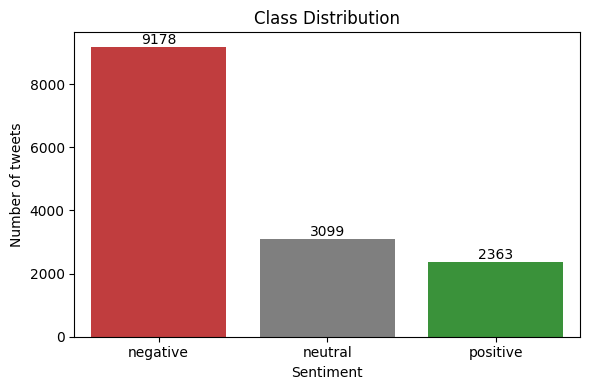

In [4]:
plt.figure(figsize=(6, 4))
ax = sns.countplot(data=data, x="airline_sentiment", hue="airline_sentiment",
                   order=ORDER, hue_order=ORDER, palette=COLORS, legend=False)
for container in ax.containers:
    ax.bar_label(container)
plt.title("Class Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of tweets")
save_fig("01_class_distribution")

Tweets per airline:
airline
United            3822
US Airways        2913
American          2759
Southwest         2420
Delta             2222
Virgin America     504


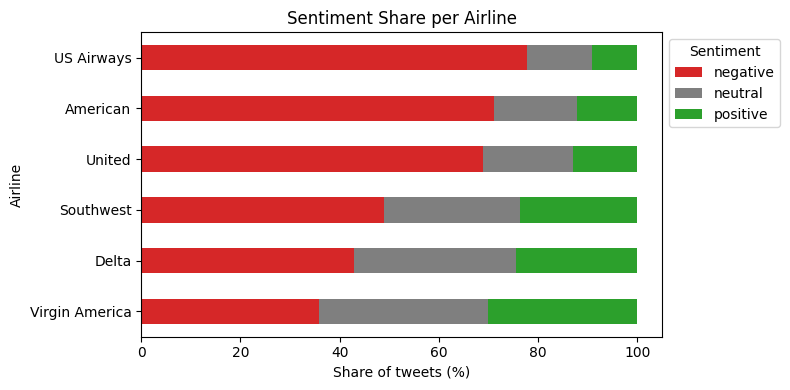

In [5]:
print("Tweets per airline:")
print(data["airline"].value_counts().to_string())

share = pd.crosstab(data["airline"], data["airline_sentiment"], normalize="index")[ORDER] * 100
share = share.sort_values("negative")
share.plot(kind="barh", stacked=True, color=COLORS, figsize=(8, 4))
plt.title("Sentiment Share per Airline")
plt.xlabel("Share of tweets (%)")
plt.ylabel("Airline")
plt.legend(title="Sentiment", bbox_to_anchor=(1, 1))
save_fig("02_sentiment_by_airline")

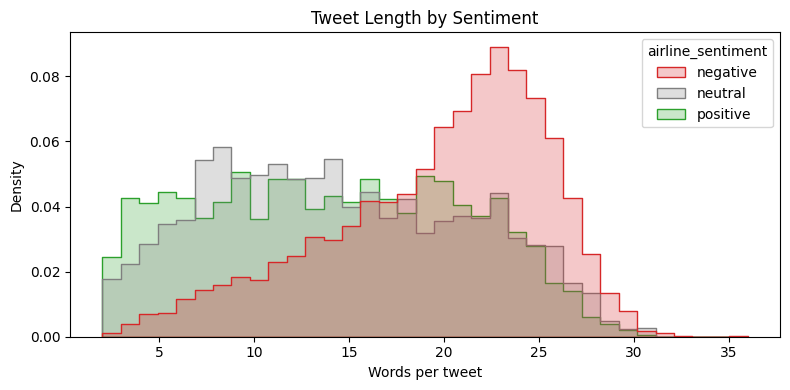

,count,mean,std,min,25%,50%,75%,max
airline_sentiment,,,,,,,,
negative,9178.0,19.7,5.9,2.0,16.0,21.0,24.0,36.0
neutral,3099.0,14.4,7.0,2.0,9.0,14.0,20.0,31.0
positive,2363.0,14.0,7.0,2.0,8.0,14.0,20.0,31.0


95% of tweets have 27 words or fewer


In [6]:
lengths = data.assign(n_words=data["text"].str.split().str.len())

plt.figure(figsize=(8, 4))
sns.histplot(data=lengths, x="n_words", hue="airline_sentiment", hue_order=ORDER,
             palette=COLORS, bins=35, element="step", stat="density", common_norm=False)
plt.title("Tweet Length by Sentiment")
plt.xlabel("Words per tweet")
save_fig("03_tweet_length")

display(lengths.groupby("airline_sentiment")["n_words"].describe().round(1))
print(f"95% of tweets have {int(lengths['n_words'].quantile(0.95))} words or fewer")

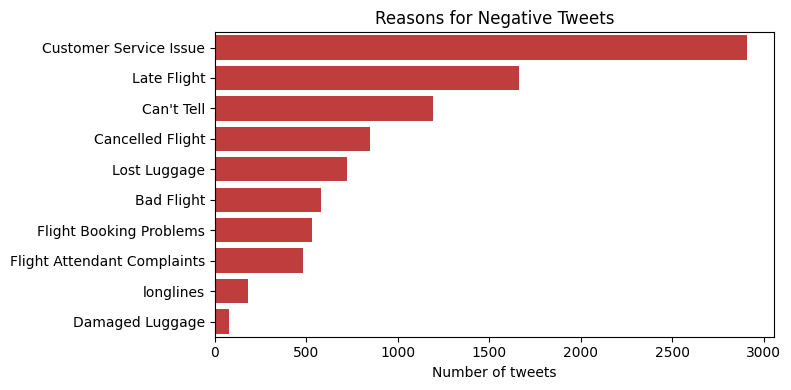

In [7]:
reasons = data.loc[data["airline_sentiment"] == "negative", "negativereason"].value_counts()

plt.figure(figsize=(8, 4))
sns.barplot(x=reasons.values, y=reasons.index, color="#d62728")
plt.title("Reasons for Negative Tweets")
plt.xlabel("Number of tweets")
plt.ylabel("")
save_fig("04_negative_reasons")

## 4. Preprocessing

In [8]:
data = data.drop_duplicates(subset="text").reset_index(drop=True)

def clean_text(text):
    text = html.unescape(text).lower()
    text = re.sub(r"http\S+|www\.\S+", " ", text)
    text = re.sub(r"@\w+", " ", text)
    text = text.replace("#", " ")
    text = re.sub(r"[^a-z0-9'!?\s]", " ", text)
    text = re.sub(r"([!?])", r" \1 ", text)
    return re.sub(r"\s+", " ", text).strip()

data["clean"] = data["text"].apply(clean_text)
empty = (data["clean"] == "").sum()
data = data[data["clean"] != ""].reset_index(drop=True)

print(f"Tweets after removing duplicates: {len(data)}")
print(f"Tweets that became empty after cleaning: {empty}")
print()
for original, cleaned in data[["text", "clean"]].sample(5, random_state=SEED).values:
    print("Original:", original)
    print("Cleaned: ", cleaned)
    print()

Tweets after removing duplicates: 14427
Tweets that became empty after cleaning: 0

Original: @JetBlue so technically I could drive to JFK now and put in. Request for tomorrow's flight?
Cleaned:  so technically i could drive to jfk now and put in request for tomorrow's flight ?

Original: @united why I won't check my carry on. Watched a handler throw this bag -- miss the conveyer belt -- sat there 10 min http://t.co/lyoocx5mSH
Cleaned:  why i won't check my carry on watched a handler throw this bag miss the conveyer belt sat there 10 min

Original: @SouthwestAir you guys are so clever 😃 http://t.co/qn5odUGFqK
Cleaned:  you guys are so clever

Original: @USAirways a year and every time with US Air something happens. I sat waiting for a re-scheduled flight for 10 hours then to say its
Cleaned:  a year and every time with us air something happens i sat waiting for a re scheduled flight for 10 hours then to say its

Original: @united 2nd time in a row  I've been over charged by 100's of $$

In [9]:
LABELS = {"negative": 0, "neutral": 1, "positive": 2}
CLASS_NAMES = list(LABELS)

X = data["clean"].values
y = data["airline_sentiment"].map(LABELS).values

idx = np.arange(len(data))
idx_train, idx_temp = train_test_split(idx, test_size=0.30, stratify=y, random_state=SEED)
idx_val, idx_test = train_test_split(idx_temp, test_size=0.50, stratify=y[idx_temp], random_state=SEED)

X_train, X_val, X_test = X[idx_train], X[idx_val], X[idx_test]
y_train, y_val, y_test = y[idx_train], y[idx_val], y[idx_test]

rows = []
for name, labels in [("Train", y_train), ("Validation", y_val), ("Test", y_test)]:
    pct = np.bincount(labels, minlength=3) / len(labels) * 100
    row = {"split": name, "tweets": len(labels)}
    row.update({f"{c} (%)": round(p, 1) for c, p in zip(CLASS_NAMES, pct)})
    rows.append(row)
display(pd.DataFrame(rows).set_index("split"))

,tweets,negative (%),neutral (%),positive (%)
split,,,,
Train,10098,62.9,21.2,15.9
Validation,2164,62.9,21.2,15.9
Test,2165,63.0,21.2,15.8


In [10]:
MAX_TOKENS = 10000
MAX_LEN = 30

vectorizer = TextVectorization(max_tokens=MAX_TOKENS, output_sequence_length=MAX_LEN, standardize=None)
vectorizer.adapt(tf.constant(X_train))
vocab = vectorizer.get_vocabulary()

X_train_seq = vectorizer(tf.constant(X_train)).numpy()
X_val_seq = vectorizer(tf.constant(X_val)).numpy()
X_test_seq = vectorizer(tf.constant(X_test)).numpy()

print(f"Vocabulary size: {len(vocab)}")
print("Most frequent tokens:", ", ".join(str(t) for t in vocab[2:27]))
print(f"Training sequences shape: {X_train_seq.shape}")
print()
print("Example tweet:", X_train[0])
print("Encoded:", X_train_seq[0].tolist())

Vocabulary size: 10000
Most frequent tokens: to, the, i, !, ?, a, you, for, flight, on, and, my, is, in, of, me, it, your, have, not, was, with, no, at, that
Training sequences shape: (10098, 30)

Example tweet: i've been on hold for 40 minutes just to get a receipt i know you guys are busy but i think it's time to higher more staff !
Encoded: [121, 42, 11, 57, 9, 449, 129, 40, 2, 28, 7, 976, 4, 106, 8, 100, 33, 670, 29, 4, 237, 82, 46, 2, 1759, 97, 205, 5, 0, 0]


In [11]:
weights = compute_class_weight("balanced", classes=np.unique(y_train), y=y_train)
class_weight = dict(enumerate(weights))

for i, w in class_weight.items():
    print(f"Class weight for {CLASS_NAMES[i]}: {w:.2f}")

Class weight for negative: 0.53
Class weight for neutral: 1.57
Class weight for positive: 2.10


## 5. Model Design

In [12]:
EMB_DIM = 64
NUM_CLASSES = 3

def compile_model(model):
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3),
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])
    return model

def build_baseline():
    inputs = keras.Input(shape=(MAX_LEN,), dtype="int64")
    x = layers.Embedding(MAX_TOKENS, EMB_DIM, mask_zero=True)(inputs)
    x = layers.GlobalAveragePooling1D()(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(32, activation="relu")(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)
    return compile_model(keras.Model(inputs, outputs, name="Baseline"))

def build_bilstm():
    inputs = keras.Input(shape=(MAX_LEN,), dtype="int64")
    x = layers.Embedding(MAX_TOKENS, EMB_DIM, mask_zero=True)(inputs)
    x = layers.Bidirectional(layers.LSTM(64))(x)
    x = layers.Dropout(0.4)(x)
    x = layers.Dense(32, activation="relu")(x)
    x = layers.Dropout(0.4)(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)
    return compile_model(keras.Model(inputs, outputs, name="BiLSTM"))

baseline = build_baseline()
bilstm = build_bilstm()
baseline.summary()
bilstm.summary()

Model: "Baseline"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 30)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 30, 64)    │    640,000 │ input_layer[0][0] │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, 30)        │          0 │ input_layer[0][0] │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 64)        │          0 │ embedding[0][0],  │
│ (GlobalAveragePool… │                   │            │ not_equal[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 64)        │          0 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 32)        │      2,080 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 32)        │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 3)         │         99 │ dropout_1[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 642,179 (2.45 MB)

 Trainable params: 642,179 (2.45 MB)

 Non-trainable params: 0 (0.00 B)

Model: "BiLSTM"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 30)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_1         │ (None, 30, 64)    │    640,000 │ input_layer_1[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_1         │ (None, 30)        │          0 │ input_layer_1[0]… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional       │ (None, 128)       │     66,048 │ embedding_1[0][0… │
│ (Bidirectional)     │                   │            │ not_equal_1[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 128)       │          0 │ bidirectional[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 32)        │      4,128 │ dropout_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_3 (Dropout) │ (None, 32)        │          0 │ dense_2[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 3)         │         99 │ dropout_3[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 710,275 (2.71 MB)

 Trainable params: 710,275 (2.71 MB)

 Non-trainable params: 0 (0.00 B)

In [13]:
probs = bilstm.predict(X_train_seq[:3], verbose=0)
print("Output shape:", probs.shape)
print("Row sums:", probs.sum(axis=1).round(3).tolist())
print("Predicted probabilities before training:")
print(probs.round(3))

Output shape: (3, 3)
Row sums: [1.0, 1.0, 1.0]
Predicted probabilities before training:
[[0.334 0.333 0.334]
 [0.334 0.332 0.333]
 [0.334 0.331 0.335]]


## 6. Training

In [14]:
def train(model, epochs=30, batch_size=64):
    early_stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)
    start = time.time()
    history = model.fit(X_train_seq, y_train,
                        validation_data=(X_val_seq, y_val),
                        epochs=epochs, batch_size=batch_size,
                        class_weight=class_weight,
                        callbacks=[early_stop], verbose=2)
    best = int(np.argmin(history.history["val_loss"])) + 1
    print()
    print(f"Training time: {time.time() - start:.1f} seconds")
    print(f"Epochs run: {len(history.history['loss'])}, best epoch: {best}")
    print(f"Best validation loss: {history.history['val_loss'][best - 1]:.4f}")
    print(f"Validation accuracy at best epoch: {history.history['val_accuracy'][best - 1]:.4f}")
    return history

hist_base = train(baseline)

Epoch 1/30
158/158 - 8s - 48ms/step - accuracy: 0.6700 - loss: 0.9699 - val_accuracy: 0.7227 - val_loss: 0.7716
Epoch 2/30
158/158 - 1s - 4ms/step - accuracy: 0.7696 - loss: 0.6470 - val_accuracy: 0.7500 - val_loss: 0.6302
Epoch 3/30
158/158 - 1s - 3ms/step - accuracy: 0.8258 - loss: 0.4937 - val_accuracy: 0.7542 - val_loss: 0.6182
Epoch 4/30
158/158 - 1s - 3ms/step - accuracy: 0.8639 - loss: 0.3965 - val_accuracy: 0.7629 - val_loss: 0.6224
Epoch 5/30
158/158 - 1s - 3ms/step - accuracy: 0.8898 - loss: 0.3282 - val_accuracy: 0.7606 - val_loss: 0.6447
Epoch 6/30
158/158 - 1s - 3ms/step - accuracy: 0.9075 - loss: 0.2767 - val_accuracy: 0.7625 - val_loss: 0.6793

Training time: 10.3 seconds
Epochs run: 6, best epoch: 3
Best validation loss: 0.6182
Validation accuracy at best epoch: 0.7542


In [15]:
hist_lstm = train(bilstm)

Epoch 1/30
158/158 - 7s - 45ms/step - accuracy: 0.6277 - loss: 0.8813 - val_accuracy: 0.7255 - val_loss: 0.6461
Epoch 2/30
158/158 - 2s - 10ms/step - accuracy: 0.7957 - loss: 0.5388 - val_accuracy: 0.7620 - val_loss: 0.5686
Epoch 3/30
158/158 - 2s - 10ms/step - accuracy: 0.8690 - loss: 0.3664 - val_accuracy: 0.7837 - val_loss: 0.6024
Epoch 4/30
158/158 - 2s - 10ms/step - accuracy: 0.9104 - loss: 0.2574 - val_accuracy: 0.7597 - val_loss: 0.8065
Epoch 5/30
158/158 - 2s - 11ms/step - accuracy: 0.9293 - loss: 0.2054 - val_accuracy: 0.7768 - val_loss: 0.8550

Training time: 13.8 seconds
Epochs run: 5, best epoch: 2
Best validation loss: 0.5686
Validation accuracy at best epoch: 0.7620


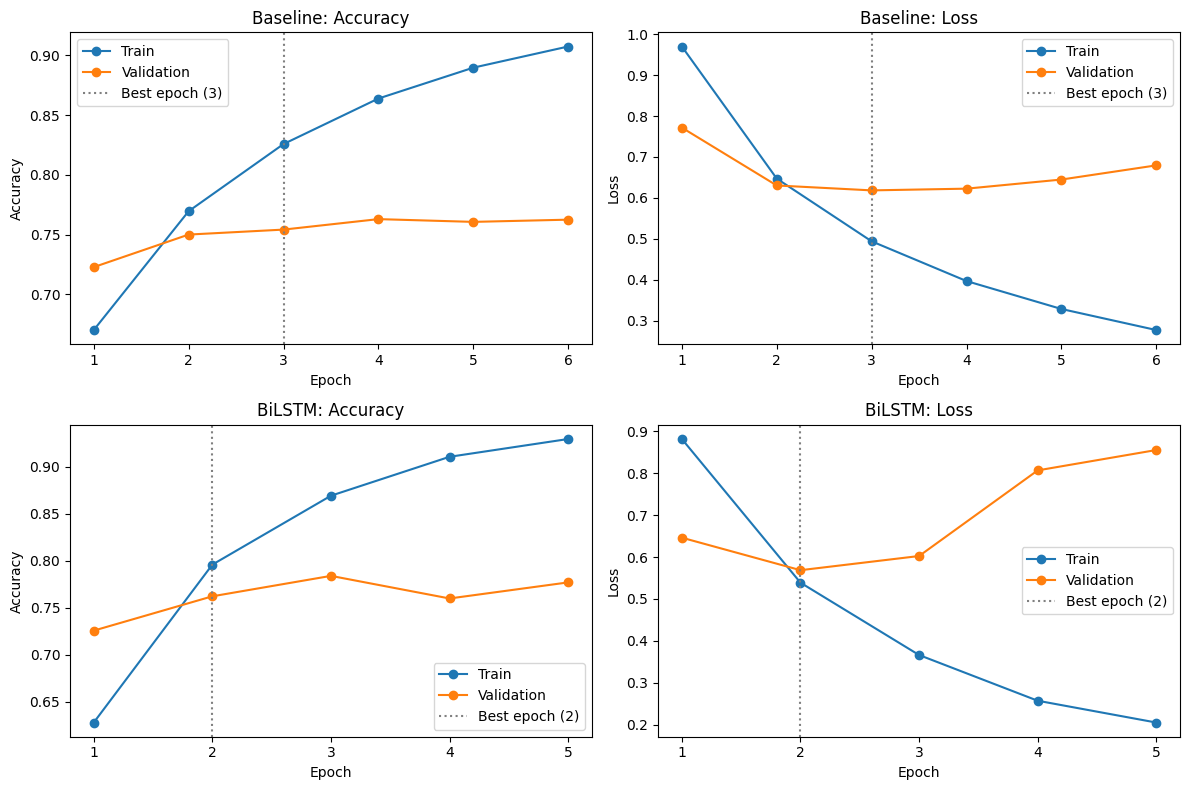

In [16]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for row, (history, name) in enumerate([(hist_base, "Baseline"), (hist_lstm, "BiLSTM")]):
    best = int(np.argmin(history.history["val_loss"])) + 1
    epochs = range(1, len(history.history["loss"]) + 1)
    for col, metric in enumerate(["accuracy", "loss"]):
        ax = axes[row, col]
        ax.plot(epochs, history.history[metric], "o-", label="Train")
        ax.plot(epochs, history.history[f"val_{metric}"], "o-", label="Validation")
        ax.axvline(best, color="gray", linestyle=":", label=f"Best epoch ({best})")
        ax.set_title(f"{name}: {metric.capitalize()}")
        ax.set_xlabel("Epoch")
        ax.set_ylabel(metric.capitalize())
        ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
        ax.legend()
save_fig("05_learning_curves")

## 7. Evaluation on the Test Set

In [17]:
preds = {
    "Majority class": np.zeros_like(y_test),
    "Baseline": baseline.predict(X_test_seq, verbose=0).argmax(axis=1),
    "BiLSTM": bilstm.predict(X_test_seq, verbose=0).argmax(axis=1),
}

rows = []
for name, pred in preds.items():
    precision, recall, f1, _ = precision_recall_fscore_support(y_test, pred, average="macro", zero_division=0)
    rows.append({"Model": name,
                 "Accuracy": accuracy_score(y_test, pred),
                 "Macro precision": precision,
                 "Macro recall": recall,
                 "Macro F1": f1,
                 "Weighted F1": f1_score(y_test, pred, average="weighted", zero_division=0)})
results = pd.DataFrame(rows).set_index("Model").round(3)
display(results)

for name in ["Baseline", "BiLSTM"]:
    print(f"Classification report: {name}")
    print(classification_report(y_test, preds[name], target_names=CLASS_NAMES, digits=3))

,Accuracy,Macro precision,Macro recall,Macro F1,Weighted F1
Model,,,,,
Majority class,0.630,0.210,0.333,0.258,0.486
Baseline,0.752,0.689,0.737,0.705,0.762
BiLSTM,0.750,0.697,0.728,0.706,0.759


Classification report: Baseline
              precision    recall  f1-score   support

    negative      0.912     0.773     0.837      1363
     neutral      0.528     0.693     0.599       459
    positive      0.627     0.743     0.680       343

    accuracy                          0.752      2165
   macro avg      0.689     0.737     0.705      2165
weighted avg      0.785     0.752     0.762      2165

Classification report: BiLSTM
              precision    recall  f1-score   support

    negative      0.892     0.778     0.832      1363
     neutral      0.517     0.697     0.594       459
    positive      0.681     0.708     0.694       343

    accuracy                          0.750      2165
   macro avg      0.697     0.728     0.706      2165
weighted avg      0.779     0.750     0.759      2165



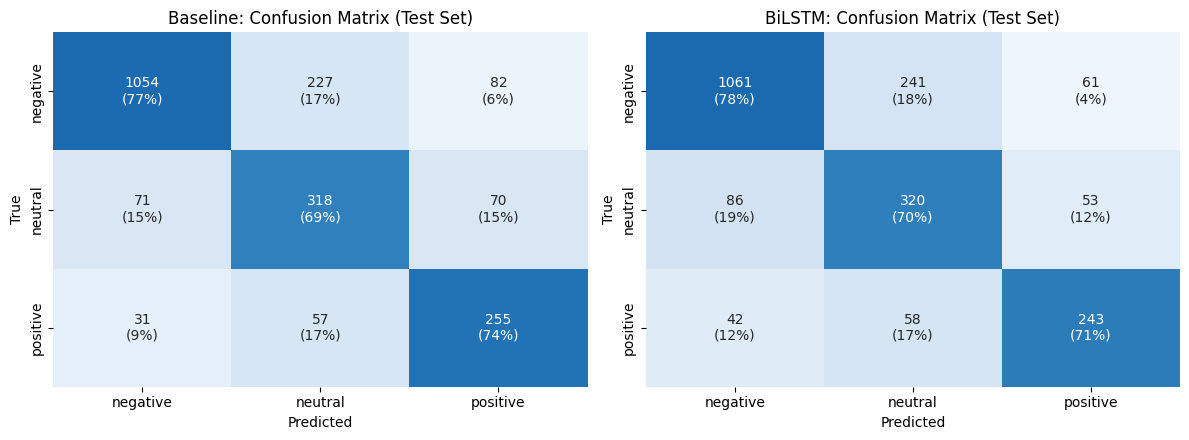

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, name in zip(axes, ["Baseline", "BiLSTM"]):
    cm = confusion_matrix(y_test, preds[name])
    cm_pct = cm / cm.sum(axis=1, keepdims=True) * 100
    annot = np.array([[f"{c}\n({p:.0f}%)" for c, p in zip(row_c, row_p)]
                      for row_c, row_p in zip(cm, cm_pct)])
    sns.heatmap(cm_pct, annot=annot, fmt="", cmap="Blues", vmin=0, vmax=100, cbar=False,
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax)
    ax.set_title(f"{name}: Confusion Matrix (Test Set)")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
save_fig("06_confusion_matrices")

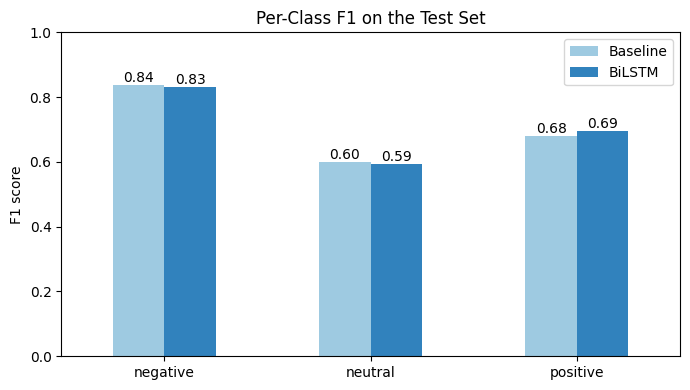

In [19]:
f1_per_class = pd.DataFrame({name: f1_score(y_test, preds[name], average=None)
                             for name in ["Baseline", "BiLSTM"]}, index=CLASS_NAMES)

ax = f1_per_class.plot(kind="bar", figsize=(7, 4), rot=0, color=["#9ecae1", "#3182bd"])
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f")
ax.set_ylim(0, 1)
ax.set_title("Per-Class F1 on the Test Set")
ax.set_ylabel("F1 score")
save_fig("07_per_class_f1")

## 8. Error Analysis (BiLSTM)

In [20]:
probs_test = bilstm.predict(X_test_seq, verbose=0)

err = data.loc[idx_test, ["text", "airline", "negativereason"]].copy()
err["true"] = [CLASS_NAMES[i] for i in y_test]
err["pred"] = [CLASS_NAMES[i] for i in probs_test.argmax(axis=1)]
err["confidence"] = probs_test.max(axis=1).round(3)
err["correct"] = err["true"] == err["pred"]

wrong = err[~err["correct"]]
print(f"Misclassified tweets: {len(wrong)} of {len(err)} ({len(wrong) / len(err) * 100:.1f}%)")
print()
print("Error types (true label -> predicted label):")
print(wrong.groupby(["true", "pred"]).size().sort_values(ascending=False).rename("tweets").to_string())

Misclassified tweets: 541 of 2165 (25.0%)

Error types (true label -> predicted label):
true      pred    
negative  neutral     241
neutral   negative     86
negative  positive     61
positive  neutral      58
neutral   positive     53
positive  negative     42


In [21]:
pd.set_option("display.max_colwidth", None)
display(wrong.sort_values("confidence", ascending=False)[["text", "true", "pred", "confidence"]].head(15))

,text,true,pred,confidence
8896,"@JetBlue Ok great thanks! I had a great flight, FYI. I'm excited to fly again. I just was frustrated I was not able to check in.",neutral,positive,0.994
8969,@USAirways we even offered to fly in to another airport and they said they couldn't do that. No explanation why they can't.,neutral,negative,0.986
987,"@united Thank you, ^JH, appreciate the prompt responses--me and other passengers will be doing so.",neutral,positive,0.985
1336,"@united basically, I need to leave from Hawaii Late Flight evening (midnight) and get back to Philly Late Flight Monday night. Most trips get me in Tues",neutral,negative,0.983
12233,"@AmericanAir the motor that usually starts the engine is broke and @CVGairport ground crew failed to do it on time, per pilot #maintenance",neutral,negative,0.981
4237,@united Is there a direct number to call to request a refund? Its telling me its not valid as I changed the ticket. No number on site,neutral,negative,0.976
8021,@JetBlue's CEO battles to appease passengers and Wall Street - Waterbury Republican American http://t.co/Ur60Un86gy,negative,neutral,0.973
10098,@USAirways i ve been told that you get a percentage on every plastic bottle that is sold around yout departure section...turn up the heat,neutral,negative,0.967
10449,@USAirways sitting on a plane in Philadelphia for over 20 minutes waiting just to get off the plane. Great service!,positive,negative,0.964
8279,@JetBlue Seems a few of my friends speak highly as well. Now we just need to find a decent priced way to go from YVR to SEA and overnight.,positive,negative,0.956


,recall,tweets
negativereason,,
Can't Tell,59.0,178
Bad Flight,72.0,107
Flight Booking Problems,76.7,73
Customer Service Issue,80.8,426
Cancelled Flight,81.2,117
Late Flight,82.1,246
Flight Attendant Complaints,84.0,75
Lost Luggage,84.0,100
longlines,85.2,27


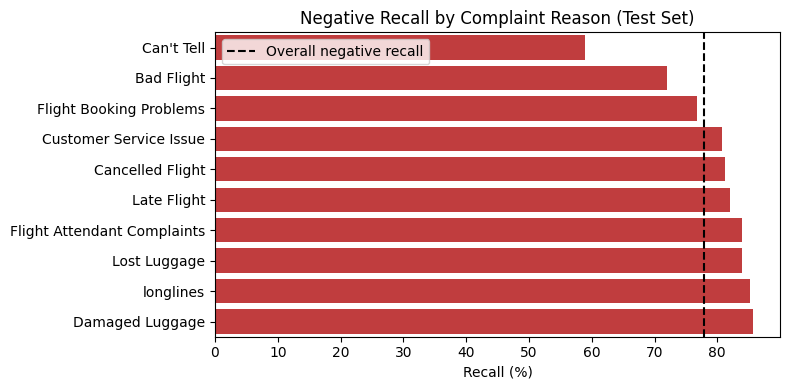

In [22]:
negatives = err[err["true"] == "negative"]
by_reason = (negatives.groupby("negativereason")["correct"]
             .agg(recall="mean", tweets="size")
             .sort_values("recall"))
by_reason["recall"] = (by_reason["recall"] * 100).round(1)
display(by_reason)

plt.figure(figsize=(8, 4))
sns.barplot(x=by_reason["recall"], y=by_reason.index, color="#d62728")
plt.axvline(negatives["correct"].mean() * 100, color="black", linestyle="--", label="Overall negative recall")
plt.title("Negative Recall by Complaint Reason (Test Set)")
plt.xlabel("Recall (%)")
plt.ylabel("")
plt.legend()
save_fig("08_recall_by_reason")

In [23]:
late = data["text"].str.contains("Late Flight").sum()
cancelled = data["text"].str.contains("Cancelled Flight").sum()
print(f"Tweets containing 'Late Flight': {late}")
print(f"Tweets containing 'Cancelled Flight': {cancelled}")
print()
print("Examples of the replacement artifact:")
for text in data.loc[data["text"].str.contains("Late Flightr|Cancelled Flighted"), "text"].head(5):
    print("-", text)

Tweets containing 'Late Flight': 447
Tweets containing 'Cancelled Flight': 999

Examples of the replacement artifact:
- @VirginAmerica our flight into lga was Cancelled Flighted. We're stuck in Dallas. I called to reschedule, told I could get a flight for today...(1/2)
- @VirginAmerica you stink. Flight Cancelled Flighted from PSP to JFK and no notification or ability to rebook #disappointed.  #expected better
- @VirginAmerica You guys charged me $100 to reschedule a flight that was then Cancelled Flighted and are now refusing to refund it. What's the deal?
- @united See? We were told repeatedly that the pilot was Late Flight and kept getting Late Flightr.  After we boarded, there was a defibrillator issue.
- @united Cancelled Flighted our flight, didn't rebook us on added flight, now have to drive from a Denver to KC....thanks!


## 9. Export Figures

In [24]:
shutil.make_archive("figures", "zip", FIG_DIR)
files.download("figures.zip")
print("Saved figures:", ", ".join(sorted(os.listdir(FIG_DIR))))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Saved figures: 01_class_distribution.png, 02_sentiment_by_airline.png, 03_tweet_length.png, 04_negative_reasons.png, 05_learning_curves.png, 06_confusion_matrices.png, 07_per_class_f1.png, 08_recall_by_reason.png
